# PMXT multi-day feasibility pilot

This notebook checks whether the fixed PMXT event universe supplies reliable opportunity labels across several days. The design fixes four six-hour blocks before their expanded outcomes are inspected. It preserves the original Dome experiment and the earlier PMXT runs. No model fitting or final-test access occurs here.

A positive hour needs a supported opportunity. A negative hour needs every basket ruled out throughout the hour. An unknown hour can contain unobservable intervals in which an opportunity cannot be ruled out. Exact value targets require coincident upper/lower peak bounds. Conditional displayed margins are not trading P&L.

See [the multi-day report](../docs/reports/pmxt_multiday_feasibility.md). The default execution only reads and verifies local artifacts; downloads use the explicit CLI commands in the report.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.common import sha256
from src.data.pmxt_archive import verify_dome

DATA = ROOT / 'data/pmxt/pilot_multiday_v1'
RESULTS = ROOT / 'results/pmxt_pilot/pilot_multiday_v1'
design = json.loads((DATA / 'study_design.json').read_text())
display(pd.DataFrame(design['blocks']))
display(verify_dome(json.loads((ROOT / 'data/pmxt/pilot_v1/dome_before.json').read_text())))

,name,start,analysis_end,warmup_start,receipt_end
0,may04,2026-05-04T01:00:00+00:00,2026-05-04T07:00:00+00:00,2026-05-04T00:00:00+00:00,2026-05-04T09:00:00+00:00
1,may06,2026-05-06T09:00:00+00:00,2026-05-06T15:00:00+00:00,2026-05-06T08:00:00+00:00,2026-05-06T17:00:00+00:00
2,may08,2026-05-08T17:00:00+00:00,2026-05-08T23:00:00+00:00,2026-05-08T16:00:00+00:00,2026-05-09T01:00:00+00:00
3,may10,2026-05-10T09:00:00+00:00,2026-05-10T15:00:00+00:00,2026-05-10T08:00:00+00:00,2026-05-10T17:00:00+00:00


{'unchanged': True, 'files': 2913}

## Original unknown-hour audit

These results explain the previously inspected 45 event-hours. Primary reasons partition unknown time. Any-cause exposure can overlap; it must not be added together as independent outages. A best-price disagreement is evidence of uncertainty, not proof of missing messages.

In [2]:
original = ROOT / 'results/pmxt_pilot/pilot_v1/unknown_audit_v1'
original_summary = json.loads((original / 'summary.json').read_text())
for name, expected in original_summary['results_sha256'].items():
    assert sha256(original / name) == expected, name
original_hours = pd.read_csv(original / 'event_hours.csv')
display(original_hours.groupby('classification').agg(
    event_hours=('hour','size'),
    unknown_labels=('label_occurrence', lambda s: s.isna().sum()),
    unknown_seconds=('unknown_seconds','sum')))
display(pd.Series(original_summary['primary_reason_seconds'], name='primary_unknown_seconds').to_frame())

,event_hours,unknown_labels,unknown_seconds
classification,,,
ladder,15,14,37883.018
negrisk,30,7,4793.758


,primary_unknown_seconds
missing_initial_snapshot,0.000
retrospective_best_price_drift,39985.781
best_price_contradiction,2690.995
crossed_final_group,0.000
malformed_group,0.000
unresolved_quantity_alternatives,0.000
other_unbounded_basket,0.000


## Expanded evidence and engineering criteria

The fixed 15-event cohort gives 360 event-hours over 24 analysis hours. Each six-hour block has one warm-up and two receipt-tail hours. The original first three analysis hours are reused; the remaining 21 hours were uninspected when the design was frozen.

Engineering targets are 95% complete ask-side event-time, 90% certified occurrence labels and a median of at least ten ask-complete events at hourly scans. These are study targets, not industry standards. They do not establish representative coverage or verified historical fee parameters. Positive-label support is reported separately.

In [3]:
summary_path = RESULTS / 'summary.json'
COMPLETE = summary_path.exists()
if not COMPLETE:
    display('Expanded analysis is incomplete. Run the frozen download, replay and feasibility commands before interpreting its results.')
else:
    summary = json.loads(summary_path.read_text())
    for category in ['evidence_sha256', 'implementation_sha256']:
        for name, expected in summary[category].items():
            assert sha256(ROOT / name.replace(chr(92), "/")) == expected, name
    # Verify nested replay manifests, raw cache, universe and audit evidence.
    from src.data.pmxt_pilot import load_plan
    for block in design['blocks']:
        folder, plan = load_plan(DATA / block['name'])
        block_results = ROOT / 'results/pmxt_pilot' / block['name']
        replay = json.loads((block_results / 'source_validation_v3/summary.json').read_text())
        run_data = folder / 'source_validation_v3'
        assert sha256(run_data / 'design.json') == replay['design_sha256']
        replay_design = json.loads((run_data / 'design.json').read_text())
        assert sha256(folder / 'plan.json') == replay_design['universe_sha256']
        for item in replay['inputs']:
            assert sha256(folder / item['path'].replace(chr(92), '/')) == item['sha256']
        for name, expected in replay['derived_sha256'].items():
            assert sha256(run_data / name) == expected, name
        for name, expected in replay['results_sha256'].items():
            assert sha256(block_results / 'source_validation_v3' / name) == expected, name
        for name, expected in replay['implementation_sha256'].items():
            assert sha256(ROOT / name.replace(chr(92), '/')) == expected, name
        audit = json.loads((block_results / 'unknown_audit_v1/summary.json').read_text())
        for name, expected in audit['implementation_sha256'].items():
            assert sha256(ROOT / name.replace(chr(92), '/')) == expected, name
        for name, expected in audit['results_sha256'].items():
            assert sha256(block_results / 'unknown_audit_v1' / name) == expected, name
    for name, expected in summary['results_sha256'].items():
        assert sha256(RESULTS / name) == expected, name
    assert summary['analysis_hours'] == 24
    assert summary['event_hours'] == 360
    assert not summary['models_trained'] and not summary['new_final_test_accessed']
    assert not summary['net_pnl_estimated']
    hours = pd.read_csv(RESULTS / 'event_hours.csv', dtype={'event_id':str})
    assert not hours.duplicated(['event_id','hour']).any()
    assert (hours.loc[hours.label_occurrence.eq(0), 'ruled_out_seconds'] >= 3600-1e-8).all()
    assert (hours.loc[hours.label_occurrence.eq(1), 'peak_value_lower_usd'] > 0).all()
    exact = hours.label_peak_value_usd.notna()
    assert np.allclose(hours.loc[exact,'peak_value_lower_usd'], hours.loc[exact,'peak_value_upper_usd'])
    display(pd.Series({k:summary[k] for k in ['event_hours','known_hours','positive_hours','negative_hours','unknown_hours','positive_event_count','candidate_episode_starts','full_ask_time_fraction','full_book_time_fraction','median_ask_complete_events_per_scan','maximum_hourly_value_lower_usd','charged_new_range_bytes','retained_raw_cache_bytes']}).to_frame('value'))
    display(pd.Series(summary['engineering_gates']).to_frame('criterion_passed'))
    display(pd.read_csv(RESULTS / 'by_classification.csv'))
    display(pd.read_csv(RESULTS / 'by_block.csv'))
    display(pd.read_csv(RESULTS / 'seed_coverage.csv'))
    seed_audit = json.loads((RESULTS / 'seed_audit.json').read_text())
    for name, expected in seed_audit['implementation_sha256'].items():
        assert sha256(ROOT / name.replace(chr(92), '/')) == expected, name

,value
event_hours,3.600000e+02
known_hours,4.300000e+01
positive_hours,2.000000e+00
negative_hours,4.100000e+01
unknown_hours,3.170000e+02
positive_event_count,1.000000e+00
candidate_episode_starts,1.200000e+01
full_ask_time_fraction,1.444182e-01
full_book_time_fraction,1.181529e-01
median_ask_complete_events_per_scan,0.000000e+00


,criterion_passed
ask_time,False
occurrence_labels,False
typical_scan_count,False


,classification,event_hours,known_hours,positive_hours,negative_hours,unknown_hours,known_fraction,full_ask_hours,full_book_hours,full_ask_time_fraction,full_book_time_fraction,determined_time_fraction,exact_value_hours,maximum_hourly_value_lower_usd,positive_seconds
0,ladder,120,5,2,3,115,0.041667,3,3,0.088786,0.069547,0.094014,3,0.8,1977.496
1,negrisk,240,38,0,38,202,0.158333,12,11,0.172234,0.142456,0.243956,38,0.0,0.000


,block,event_hours,known_hours,positive_hours,negative_hours,unknown_hours,known_fraction,full_ask_hours,full_book_hours,full_ask_time_fraction,full_book_time_fraction,determined_time_fraction,exact_value_hours,maximum_hourly_value_lower_usd,positive_seconds
0,may04,90,39,0,39,51,0.433333,15,14,0.558559,0.462324,0.738938,39,0.0,0.000
1,may06,90,4,2,2,86,0.044444,0,0,0.019114,0.010287,0.036963,2,0.8,1977.496
2,may08,90,0,0,0,90,0.000000,0,0,0.000000,0.000000,0.000000,0,0.0,0.000
3,may10,90,0,0,0,90,0.000000,0,0,0.000000,0.000000,0.000000,0,0.0,0.000


,block,raw_book_messages,unique_book_source_groups,books_before_source_capture,assets_with_any_book,assets_seeded_before_first_scan,assets_seeded_before_analysis_end,assets_without_any_qualifying_book,price_updates_before_seed,price_updates_in_capture_analysis,unseeded_update_fraction,median_book_receipt_lag_seconds,p99_book_receipt_lag_seconds
0,may04,39415,27565,79,200,200,200,0,13267,1306357,0.010156,26.8660,1049.59222
1,may06,401,393,0,172,2,172,28,786579,1091526,0.720623,37.3410,727.98900
2,may08,84,83,0,68,3,58,132,724536,820940,0.882569,29.3045,957.58956
3,may10,31,31,0,28,4,18,172,681707,701069,0.972382,39.4200,422.47290


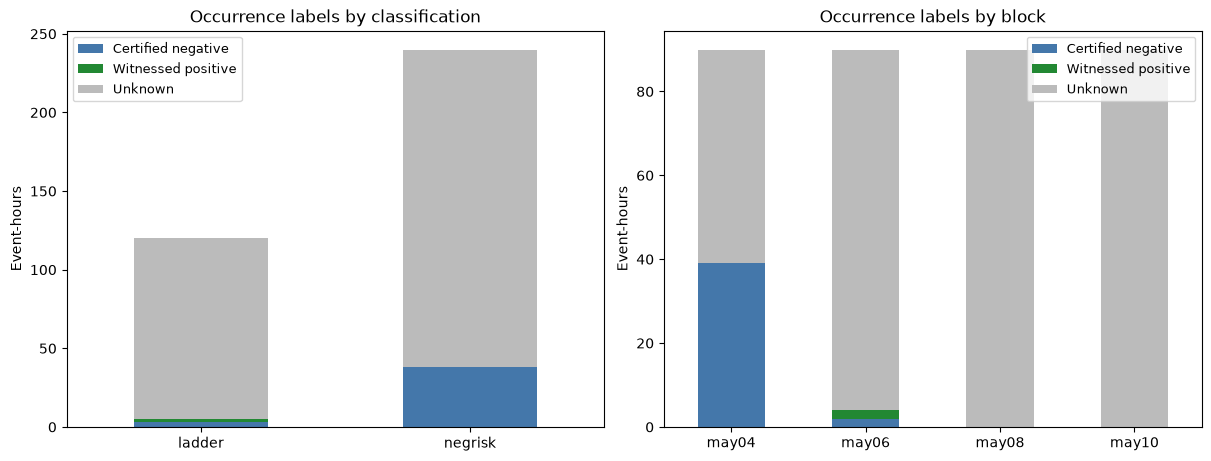

,reason,primary_unknown_seconds,overlapping_unknown_seconds
0,missing_initial_snapshot,943850.415,943850.415
1,retrospective_best_price_drift,93428.365,425124.672
2,best_price_contradiction,7329.055,134854.978
3,crossed_final_group,0.000,0.000
4,malformed_group,0.000,0.000
5,unresolved_quantity_alternatives,0.000,1157.931
6,other_unbounded_basket,0.000,0.000


,event_id,event_slug,classification,event_hours,known_hours,positive_hours,negative_hours,unknown_hours,known_fraction,full_ask_hours,full_book_hours,full_ask_time_fraction,full_book_time_fraction,determined_time_fraction,exact_value_hours,maximum_hourly_value_lower_usd,positive_seconds
0,106981,bitcoin-vs-gold-vs-sp-500-in-2026,negrisk,24,3,0,3,21,0.125000,3,3,0.230452,0.210386,0.230452,3,0.0,0.000
1,200252,openai-ipo-closing-market-cap-554,negrisk,24,6,0,6,18,0.250000,0,0,0.110994,0.083708,0.257413,6,0.0,0.000
2,201560,india-annual-inflation-2026,negrisk,24,3,0,3,21,0.125000,0,0,0.139424,0.124959,0.237995,3,0.0,0.000
3,204610,of-seats-won-by-ppp-in-south-korea-by-elections,negrisk,24,1,0,1,23,0.041667,1,0,0.181800,0.121711,0.183349,1,0.0,0.000
4,228259,how-many-tornadoes-in-the-us-in-2026,negrisk,24,6,0,6,18,0.250000,2,2,0.263723,0.198282,0.287295,6,0.0,0.000
5,230330,us-trade-deficit-in-2026,negrisk,24,4,0,4,20,0.166667,0,0,0.133591,0.090642,0.232619,4,0.0,0.000
6,401356,colombia-presidential-election-1st-round-turnout,negrisk,24,4,0,4,20,0.166667,0,0,0.174330,0.174330,0.257730,4,0.0,0.000
7,417522,chi1-edv-ccu-2026-05-22,negrisk,24,7,0,7,17,0.291667,6,6,0.288578,0.288578,0.298865,7,0.0,0.000
8,438065,what-price-will-bitcoin-hit-in-may-2026,ladder,24,0,0,0,24,0.000000,0,0,0.053118,0.018453,0.055205,0,0.0,0.000
9,438066,what-price-will-ethereum-hit-in-may-2026,ladder,24,0,0,0,24,0.000000,0,0,0.064201,0.048359,0.065275,0,0.0,0.000


In [4]:
if COMPLETE:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    for ax, filename, key in zip(axes, ['by_classification.csv','by_block.csv'], ['classification','block']):
        table = pd.read_csv(RESULTS / filename).set_index(key)
        table[['negative_hours','positive_hours','unknown_hours']].plot.bar(stacked=True, ax=ax,
            color=['#4477AA','#228833','#BBBBBB'], rot=0)
        ax.set_ylabel('Event-hours')
        ax.set_xlabel('')
        ax.set_title('Occurrence labels by ' + key)
        ax.legend(['Certified negative','Witnessed positive','Unknown'], fontsize=9)
    plt.show()
    display(pd.read_csv(RESULTS / 'unknown_reasons.csv'))
    display(pd.read_csv(RESULTS / 'by_event.csv'))

## Interpretation limits

The universe was selected from identifiers present on 4 May and is not a representative sample of all Polymarket events. The catalogue is incomplete, and the five ladders are concentrated in cryptocurrency threshold markets. Never discard events because their inspected opportunities are small or their labels are inconvenient.

The native source clock assumes a hypothetical timely feed. Finite receipt buffers and internal consistency cannot prove complete depth capture. Historical membership, fees, tick sizes and minimum quantities remain unverified. Quote labels use zero fees, a five-share minimum and an initial 0.0001 tick until an observed change. The supported baskets use minimum guaranteed payouts and do not cover every possible trading strategy.

The feature export is an adapter diagnostic, not the complete Dome training schema. No PMXT models or profitability claims follow from this notebook. A later economic comparison would use 100 ms total source-update-to-order-arrival latency, uncapped capital and displayed-depth constraints, with explicit latency sensitivities.

The expanded starting-book audit distinguishes capture limitations from initialization limitations. An hourly file does not guarantee a complete initial book for every token. Continuous earlier history may supply the missing seeds; every intervening update must also be replayed. A longer warm-up is not a substitute for validating contradictions after a seed exists.